In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/hmnist_8_8_RGB.csv
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/hmnist_28_28_RGB.csv
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/hmnist_8_8_L.csv
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/hmnist_28_28_L.csv
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_metadata.csv
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0028933.jpg
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0028394.jpg
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0027799.jpg
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0028100.jpg
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0027960.jpg
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0028872.jpg
/kaggle/input/datasets/kmader/skin-

In [2]:

 
# ── CELL 1: Imports & Config ─────────────────────────────────
import os, sys, warnings, glob, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from collections import Counter
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as transforms
import torchvision.models as models
 
os.system('pip install timm albumentations -q')
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2
 
warnings.filterwarnings('ignore')
 
plt.rcParams.update({
    'figure.facecolor': '#0f0f0f',
    'axes.facecolor':   '#1a1a1a',
    'axes.edgecolor':   '#444',
    'axes.labelcolor':  'white',
    'xtick.color':      'white',
    'ytick.color':      'white',
    'text.color':       'white',
    'legend.facecolor': '#1a1a1a',
    'legend.edgecolor': '#444',
})
 
PALETTE     = ['#00d4ff','#ff6b6b','#51cf66','#ffd43b','#cc5de8','#ff922b','#74c0fc']
BASE_PATH   = '/kaggle/input/skin-cancer-mnist-ham10000'
MEAN        = [0.756, 0.555, 0.582]
STD         = [0.103, 0.079, 0.090]
IMG_SIZE    = 224
BATCH_SIZE  = 32
NUM_EPOCHS  = 30
NUM_CLASSES = 7
LR          = 1e-4
DEVICE      = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
 
CLASS_INFO = {
    'nv':    ('Melanocytic Nevi',       'Benign',    '#74c0fc'),
    'mel':   ('Melanoma',               'Malignant', '#ff6b6b'),
    'bkl':   ('Benign Keratosis',       'Benign',    '#51cf66'),
    'bcc':   ('Basal Cell Carcinoma',   'Malignant', '#ffd43b'),
    'akiec': ('Actinic Keratosis',      'Malignant', '#cc5de8'),
    'vasc':  ('Vascular Lesions',       'Benign',    '#ff922b'),
    'df':    ('Dermatofibroma',         'Benign',    '#00d4ff'),
}
CLASS_TO_IDX = {cls: idx for idx, cls in enumerate(CLASS_INFO.keys())}
IDX_TO_CLASS = {idx: cls for cls, idx in CLASS_TO_IDX.items()}
 

print(f"  Device      : {DEVICE}")
if torch.cuda.is_available():
    print(f"  GPU         : {torch.cuda.get_device_name(0)}")
    print(f"  VRAM        : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
print(f"  Image Size  : {IMG_SIZE}x{IMG_SIZE}")
print(f"  Batch Size  : {BATCH_SIZE}")
print(f"  Max Epochs  : {NUM_EPOCHS}")
print(f"  Learning Rate: {LR}")
print("=" * 60)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 99.1 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cudf-cu12 26.2.1 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cudf-cu12 26.2.1 requires numba-cuda[cu12]<0.23.0,>=0.22.2, but you hav

  Device      : cuda
  GPU         : Tesla T4
  VRAM        : 15.6 GB
  Image Size  : 224x224
  Batch Size  : 32
  Max Epochs  : 30
  Learning Rate: 0.0001


In [3]:
# ── CELL 2: Load & Prepare Data ──────────────────────────────

# Explicitly set the corrected BASE_PATH
BASE_PATH = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000'

def load_ham10000(base_path):
    """Load HAM10000 metadata and image paths."""
    meta_path = os.path.join(base_path, 'HAM10000_metadata.csv')
    df = pd.read_csv(meta_path)
 
    # Map image paths from both image folders
    img_dirs = [
        os.path.join(base_path, 'HAM10000_images_part_1'),
        os.path.join(base_path, 'HAM10000_images_part_2'),
        # Note: If images still aren't loading, check if these folders 
        # are completely lowercase in your Kaggle environment (e.g., 'ham10000_images_part_1')
    ]
    img_map = {}
    for d in img_dirs:
        if os.path.exists(d):
            for f in os.listdir(d):
                if f.endswith('.jpg'):
                    img_map[f.replace('.jpg', '')] = os.path.join(d, f)
 
    df['path'] = df['image_id'].map(img_map)
    df = df.dropna(subset=['path'])
    df['label'] = df['dx'].map(CLASS_TO_IDX)
    df = df.dropna(subset=['label'])
    df['label'] = df['label'].astype(int)
 
    print(f"  Total images loaded : {len(df)}")
    return df
 
df = load_ham10000(BASE_PATH)
 
# ── Stratified split (same seed as Day 3 for consistency) ────
# ── Stratified split: Train / Validation / Test = 70 / 15 / 15 ──

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df['label']
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df['label']
)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

class_counts = Counter(train_df['label'].tolist())

print("=" * 60)
print("DATASET SPLIT COMPLETED")
print("=" * 60)
print(f"  Train size : {len(train_df)}")
print(f"  Val size   : {len(val_df)}")
print(f"  Test size  : {len(test_df)}")

print(f"\n  Class distribution (train):")
for idx, (cls, (name, _, _)) in enumerate(CLASS_INFO.items()):
    print(f"    [{idx}] {cls:6s} ({name:25s}): {class_counts[idx]:4d}")

  Total images loaded : 10015
DATASET SPLIT COMPLETED
  Train size : 7010
  Val size   : 1502
  Test size  : 1503

  Class distribution (train):
    [0] nv     (Melanocytic Nevi         ): 4693
    [1] mel    (Melanoma                 ):  779
    [2] bkl    (Benign Keratosis         ):  769
    [3] bcc    (Basal Cell Carcinoma     ):  360
    [4] akiec  (Actinic Keratosis        ):  229
    [5] vasc   (Vascular Lesions         ):   99
    [6] df     (Dermatofibroma           ):   81


In [ ]:
# Advanced dermatology preprocessing
import cv2

APPLY_ADVANCED_PREPROCESSING = True

def remove_hair(image):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (17, 17))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
    _, threshold = cv2.threshold(blackhat, 10, 255, cv2.THRESH_BINARY)
    return cv2.inpaint(image, threshold, 1, cv2.INPAINT_TELEA)

def apply_clahe(image):
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    return cv2.cvtColor(cv2.merge((clahe.apply(l), a, b)), cv2.COLOR_LAB2RGB)

def segment_lesion(image):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    _, mask = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    kernel = np.ones((5, 5), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    return cv2.bitwise_and(image, image, mask=mask)

def edge_enhancement(image):
    gaussian = cv2.GaussianBlur(image, (0, 0), 3)
    return cv2.addWeighted(image, 1.5, gaussian, -0.5, 0)

def advanced_preprocess(image):
    image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
    image = remove_hair(image)
    image = apply_clahe(image)
    image = cv2.GaussianBlur(image, (3, 3), 0)
    image = cv2.medianBlur(image, 3)
    image = cv2.bilateralFilter(image, 9, 75, 75)
    image = segment_lesion(image)
    image = edge_enhancement(image)
    return np.clip(image, 0, 255).astype(np.uint8)


In [4]:
# ── CELL 3: Stronger Augmentation (fixes Day 3 overfitting) ──
# Day 3 likely used basic torchvision transforms.
# Here we use albumentations for stronger, more diverse augmentation.
 
train_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.RandomRotate90(p=0.5),
    A.HorizontalFlip(p=0.5),  # <-- Replaced A.Flip()
    A.VerticalFlip(p=0.5),    # <-- Added vertical flip to match previous behavior
    A.Transpose(p=0.3),
    A.ShiftScaleRotate(
        shift_limit=0.1, scale_limit=0.15,
        rotate_limit=45, p=0.6
    ),
    A.OneOf([
        A.ElasticTransform(alpha=1, sigma=50, p=0.5),
        A.GridDistortion(p=0.5),
        A.OpticalDistortion(distort_limit=0.5, p=0.5),
    ], p=0.3),
    A.OneOf([
        A.GaussNoise(p=0.5),
        A.GaussianBlur(blur_limit=3, p=0.5),
        A.MotionBlur(blur_limit=3, p=0.5),
    ], p=0.4),
    A.OneOf([
        A.RandomBrightnessContrast(brightness_limit=0.3,
                                   contrast_limit=0.3, p=0.5),
        A.HueSaturationValue(hue_shift_limit=20,
                             sat_shift_limit=30,
                             val_shift_limit=20, p=0.5),
        A.ColorJitter(brightness=0.2, contrast=0.2,
                      saturation=0.2, hue=0.1, p=0.5),
    ], p=0.5),
    A.CoarseDropout(
        max_holes=8, max_height=32, max_width=32,
        min_holes=1, fill_value=0, p=0.4           # Cutout regularization
    ),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])
 
val_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

test_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])
print("=" * 60)
print("  AUGMENTATION PIPELINE (Albumentations)")
print("=" * 60)
print("  Train: Rotate90 | H/V Flips | ShiftScaleRotate | Elastic")
print("         GaussNoise | Blur | Brightness | ColorJitter")
print("         CoarseDropout (Cutout) | Normalize")
print("  Val  : Resize | Normalize only")
print("=" * 60)

  AUGMENTATION PIPELINE (Albumentations)
  Train: Rotate90 | H/V Flips | ShiftScaleRotate | Elastic
         GaussNoise | Blur | Brightness | ColorJitter
         CoarseDropout (Cutout) | Normalize
  Val  : Resize | Normalize only


In [5]:
# ── CELL 4: Dataset ──────────────────────────────────────────

class HAM10000Dataset(Dataset):
    def __init__(self, dataframe, transform=None, advanced_preprocessing=False):
        self.df        = dataframe
        self.transform = transform
        self.advanced_preprocessing = advanced_preprocessing

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        image = np.array(Image.open(row['path']).convert('RGB'))
        label = int(row['label'])

        if self.advanced_preprocessing:
            image = advanced_preprocess(image)

        if self.transform:
            image = self.transform(image=image)['image']

        return image, label


# ── Weighted sampler for class imbalance ─────────────────────
# Imbalance is handled only on training data.

class_counts_list = [class_counts[i] for i in range(NUM_CLASSES)]

sample_weights = [
    1.0 / class_counts_list[label]
    for label in train_df['label'].tolist()
]

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

print("=" * 70)
print("IMBALANCE HANDLING USING WEIGHTED RANDOM SAMPLER")
print("=" * 70)

for i in range(NUM_CLASSES):
    class_code = IDX_TO_CLASS[i]
    class_name = CLASS_INFO[class_code][0]
    count = class_counts_list[i]
    weight = 1.0 / count

    print(f"Class Index : {i}")
    print(f"Class Code  : {class_code}")
    print(f"Class Name  : {class_name}")
    print(f"Image Count : {count}")
    print(f"Weight      : {weight:.8f}")

    if count == min(class_counts_list):
        print("Status      : Minority class, higher sampling chance")
    elif count == max(class_counts_list):
        print("Status      : Majority class, lower sampling chance")
    else:
        print("Status      : Medium class")

    print("-" * 70)

print("WeightedRandomSampler created successfully.")
print("Minority classes are assigned higher weights.")
print("Majority classes are assigned lower weights.")
print("This helps the model see minority-class images more frequently during training.")
print("=" * 70)


train_dataset = HAM10000Dataset(train_df, transform=train_transform, advanced_preprocessing=APPLY_ADVANCED_PREPROCESSING)
val_dataset   = HAM10000Dataset(val_df,   transform=val_transform,   advanced_preprocessing=APPLY_ADVANCED_PREPROCESSING)
test_dataset  = HAM10000Dataset(test_df,  transform=test_transform,  advanced_preprocessing=APPLY_ADVANCED_PREPROCESSING)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print(f"  Train batches : {len(train_loader)}")
print(f"  Val batches   : {len(val_loader)}")
print(f"  Test batches  : {len(test_loader)}")
print("  DataLoaders ready!")

IMBALANCE HANDLING USING WEIGHTED RANDOM SAMPLER
Class Index : 0
Class Code  : nv
Class Name  : Melanocytic Nevi
Image Count : 4693
Weight      : 0.00021308
Status      : Majority class, lower sampling chance
----------------------------------------------------------------------
Class Index : 1
Class Code  : mel
Class Name  : Melanoma
Image Count : 779
Weight      : 0.00128370
Status      : Medium class
----------------------------------------------------------------------
Class Index : 2
Class Code  : bkl
Class Name  : Benign Keratosis
Image Count : 769
Weight      : 0.00130039
Status      : Medium class
----------------------------------------------------------------------
Class Index : 3
Class Code  : bcc
Class Name  : Basal Cell Carcinoma
Image Count : 360
Weight      : 0.00277778
Status      : Medium class
----------------------------------------------------------------------
Class Index : 4
Class Code  : akiec
Class Name  : Actinic Keratosis
Image Count : 229
Weight      : 0.0043

In [6]:
# ── CELL 5: ResNet50 Model ───────────────────────────────────
def build_resnet50(num_classes=7, pretrained=True):
    """
    ResNet50 with:
      - All layers unfrozen from epoch 5 (gradual unfreeze)
      - Custom head: Dropout → FC → BN → ReLU → Dropout → FC
      - Label smoothing built into loss
    """
    model = models.resnet50(weights='IMAGENET1K_V2' if pretrained else None)
 
    # Phase 1: Freeze all but layer4 + FC
    for name, param in model.named_parameters():
        if not any(k in name for k in ['layer4', 'fc']):
            param.requires_grad = False
 
    in_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Dropout(p=0.5),
        nn.Linear(in_features, 512),
        nn.ReLU(inplace=True),
        nn.BatchNorm1d(512),
        nn.Dropout(p=0.3),
        nn.Linear(512, 256),
        nn.ReLU(inplace=True),
        nn.Dropout(p=0.2),
        nn.Linear(256, num_classes)
    )
    return model
 
model = build_resnet50(num_classes=NUM_CLASSES)
model = model.to(DEVICE)
 
total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
frozen_params    = total_params - trainable_params
 
print("=" * 60)
print("  MODEL: ResNet50 (ImageNet V2 Weights)")
print("=" * 60)
print(f"  Total params     : {total_params:,}")
print(f"  Trainable params : {trainable_params:,}  (layer4 + FC)")
print(f"  Frozen params    : {frozen_params:,}  (layer1-3)")
print(f"  Head             : FC(2048→512) → BN → FC(512→256) → FC(256→7)")
print(f"  Dropout          : 0.5 + 0.3 + 0.2")
print("=" * 60)
 


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 197MB/s] 


  MODEL: ResNet50 (ImageNet V2 Weights)
  Total params     : 24,691,271
  Trainable params : 16,147,975  (layer4 + FC)
  Frozen params    : 8,543,296  (layer1-3)
  Head             : FC(2048→512) → BN → FC(512→256) → FC(256→7)
  Dropout          : 0.5 + 0.3 + 0.2


In [7]:
# ── CELL 6: Loss, Optimizer, Scheduler ───────────────────────
# Label smoothing (0.1) prevents overconfident predictions → reduces overfitting
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
 
# Phase 1 optimizer — only train layer4 + head
optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LR,
    weight_decay=1e-3
)
 
# OneCycleLR: ramps up then decays — best for fine-tuning
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr          = LR,
    steps_per_epoch = len(train_loader),
    epochs          = NUM_EPOCHS,
    pct_start       = 0.2,          # 20% warmup
    anneal_strategy = 'cos',
    cycle_momentum  = False         # <-- FIX: Prevents momentum key crashes when unfreezing
)
 
print("=" * 60)
print("  TRAINING SETUP")
print("=" * 60)
print(f"  Loss      : CrossEntropyLoss (label_smoothing=0.1)")
print(f"  Optimizer : AdamW (lr={LR}, wd=1e-3)")
print(f"  Scheduler : OneCycleLR (max_lr={LR}, 20% warmup, cycle_momentum=False)")
print(f"  Strategy  : Freeze layer1-3 for 5 epochs, then unfreeze all")
print("=" * 60)

  TRAINING SETUP
  Loss      : CrossEntropyLoss (label_smoothing=0.1)
  Optimizer : AdamW (lr=0.0001, wd=1e-3)
  Scheduler : OneCycleLR (max_lr=0.0001, 20% warmup, cycle_momentum=False)
  Strategy  : Freeze layer1-3 for 5 epochs, then unfreeze all


In [8]:
# ── CELL 7: Training & Validation Functions ──────────────────
def train_one_epoch(model, loader, criterion, optimizer, scheduler, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
 
    for batch_idx, (images, labels) in enumerate(loader):
        images, labels = images.to(device), labels.to(device)
 
        optimizer.zero_grad()
        outputs = model(images)
        loss    = criterion(outputs, labels)
        loss.backward()
 
        # Gradient clipping to stabilize training
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
 
        optimizer.step()
        scheduler.step()   # OneCycleLR steps per batch
 
        total_loss += loss.item()
        preds       = outputs.argmax(dim=1)
        correct    += (preds == labels).sum().item()
        total      += labels.size(0)
 
        if (batch_idx + 1) % 50 == 0:
            print(f"    Batch [{batch_idx+1:3d}/{len(loader)}]  "
                  f"Loss: {total_loss/(batch_idx+1):.4f}  "
                  f"Acc: {correct/total*100:.2f}%  "
                  f"LR: {scheduler.get_last_lr()[0]:.2e}")
 
    return total_loss / len(loader), correct / total * 100
 
 
def validate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
 
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss    = criterion(outputs, labels)
 
            total_loss += loss.item()
            preds       = outputs.argmax(dim=1)
            correct    += (preds == labels).sum().item()
            total      += labels.size(0)
 
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
 
    val_loss = total_loss / len(loader)
    val_acc  = correct / total * 100
    return val_loss, val_acc, all_preds, all_labels
 
 
def unfreeze_all(model, optimizer, new_lr=5e-5):
    """Unfreeze all layers after initial phase — gradual unfreeze strategy."""
    for param in model.parameters():
        param.requires_grad = True
 
    # Add newly unfrozen params to optimizer with the keys OneCycleLR expects
    optimizer.add_param_group({
        'params': [p for p in model.parameters()
                   if not any(p is pg for pg in
                   [q for group in optimizer.param_groups
                    for q in group['params']])],
        'lr': new_lr,
        'initial_lr': new_lr,  # FIX: Prevents OneCycleLR KeyError
        'max_lr': new_lr,      # FIX: Prevents OneCycleLR KeyError
        'min_lr': 1e-7         # FIX: Prevents OneCycleLR KeyError
    })
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"\n  *** ALL LAYERS UNFROZEN — Trainable: {trainable:,} params ***\n")

In [9]:
# ── CELL 8: Main Training Loop ───────────────────────────────
history = {
    'train_loss': [], 'val_loss': [],
    'train_acc':  [], 'val_acc':  [],
    'lr':         []
}
 
best_val_acc     = 0.0
best_model_wts   = copy.deepcopy(model.state_dict())
patience         = 8
patience_counter = 0
UNFREEZE_EPOCH   = 5   # Unfreeze all layers after epoch 5
 
print("=" * 60)
print("  TRAINING STARTED — ResNet50")
print("  Strategy: Freeze layer1-3 for 5 epochs, then full fine-tune")
print("=" * 60)
 
for epoch in range(NUM_EPOCHS):
    start = time.time()
 
    # ── Gradual unfreeze at epoch 5 ──────────────────────────
    if epoch == UNFREEZE_EPOCH:
        unfreeze_all(model, optimizer, new_lr=5e-5)
 
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, scheduler, DEVICE
    )
    val_loss, val_acc, _, _ = validate(
        model, val_loader, criterion, DEVICE
    )
 
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)
    history['lr'].append(scheduler.get_last_lr()[0])
 
    elapsed = time.time() - start
 
    if val_acc > best_val_acc:
        best_val_acc   = val_acc
        best_model_wts = copy.deepcopy(model.state_dict())
        patience_counter = 0
        # This path is correct for Kaggle!
        torch.save(model.state_dict(), '/kaggle/working/best_resnet50.pth')
        saved = "★ BEST MODEL SAVED ★"
    else:
        patience_counter += 1
        saved = f"(patience {patience_counter}/{patience})"
 
    phase = "FROZEN" if epoch < UNFREEZE_EPOCH else "FULL  "
    print(f"[{phase}] Epoch [{epoch+1:2d}/{NUM_EPOCHS}]  "
          f"Train: {train_acc:.2f}%  "
          f"Val: {val_acc:.2f}%  "
          f"Loss: {val_loss:.4f}  "
          f"Time: {elapsed:.1f}s  {saved}")
 
    if patience_counter >= patience:
        print(f"\n  Early stopping at epoch {epoch+1}")
        break
 
print("=" * 60)
print("  TRAINING STARTED — ResNet50")
print("  Split: 70% Train, 15% Validation, 15% Test")
print("  Imbalance Handling: WeightedRandomSampler only")
print("  Loss Function: CrossEntropyLoss(label_smoothing=0.1)")
print("  Strategy: Freeze layer1-3 for 5 epochs, then full fine-tune")
print("=" * 60)
 
model.load_state_dict(best_model_wts)

  TRAINING STARTED — ResNet50
  Strategy: Freeze layer1-3 for 5 epochs, then full fine-tune
    Batch [ 50/220]  Loss: 1.9923  Acc: 12.50%  LR: 4.34e-06
    Batch [100/220]  Loss: 1.9870  Acc: 13.75%  LR: 5.36e-06
    Batch [150/220]  Loss: 1.9798  Acc: 14.15%  LR: 7.03e-06
    Batch [200/220]  Loss: 1.9740  Acc: 14.73%  LR: 9.34e-06
[FROZEN] Epoch [ 1/30]  Train: 14.95%  Val: 32.36%  Loss: 1.8820  Time: 71.0s  ★ BEST MODEL SAVED ★
    Batch [ 50/220]  Loss: 1.9387  Acc: 17.25%  LR: 1.36e-05
    Batch [100/220]  Loss: 1.9286  Acc: 18.97%  LR: 1.73e-05
    Batch [150/220]  Loss: 1.9112  Acc: 21.00%  LR: 2.15e-05
    Batch [200/220]  Loss: 1.8956  Acc: 22.78%  LR: 2.61e-05
[FROZEN] Epoch [ 2/30]  Train: 23.95%  Val: 47.60%  Loss: 1.7336  Time: 61.1s  ★ BEST MODEL SAVED ★
    Batch [ 50/220]  Loss: 1.7402  Acc: 36.44%  LR: 3.31e-05
    Batch [100/220]  Loss: 1.7120  Acc: 37.94%  LR: 3.85e-05
    Batch [150/220]  Loss: 1.6811  Acc: 39.50%  LR: 4.41e-05
    Batch [200/220]  Loss: 1.6487  Ac

<All keys matched successfully>

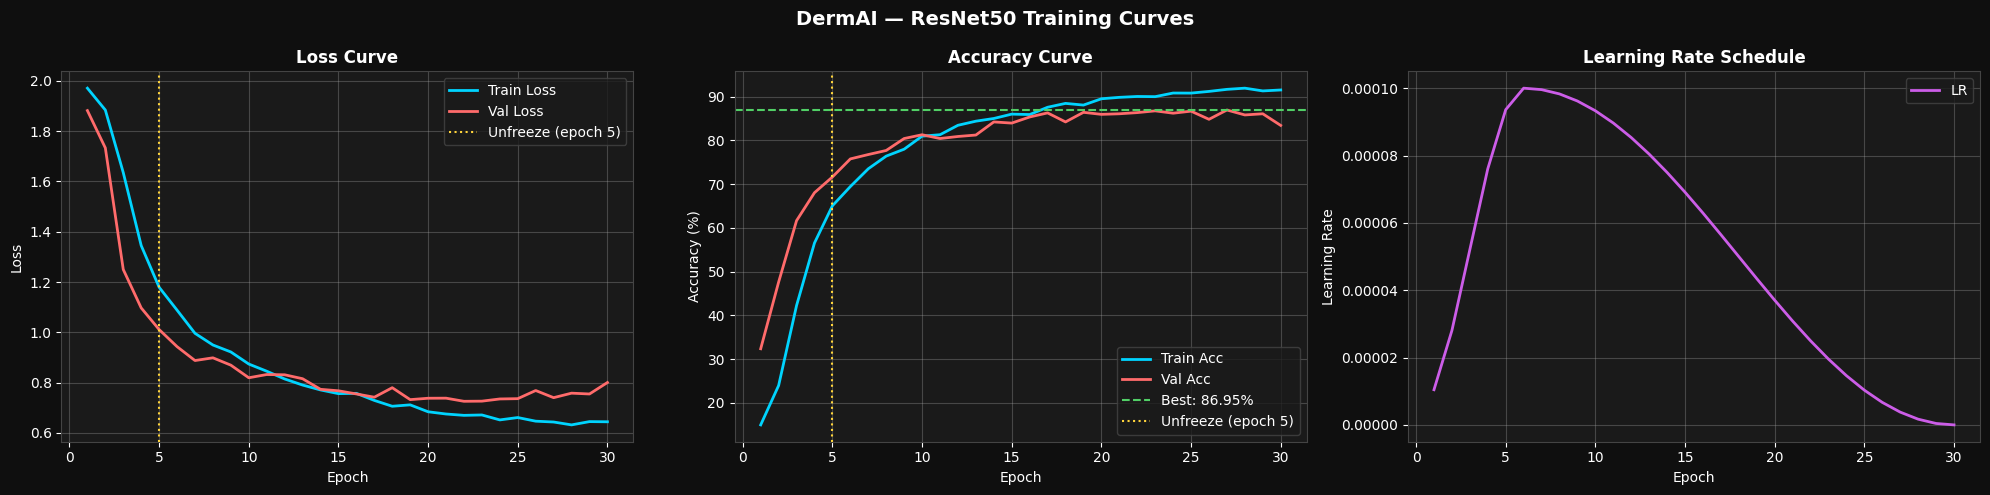

Training curves saved!


In [10]:
# ── CELL 9: Training Curves ──────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
fig.suptitle('DermAI — ResNet50 Training Curves',
             fontsize=14, fontweight='bold', color='white')
fig.patch.set_facecolor('#0f0f0f')
 
epochs_range = range(1, len(history['train_loss']) + 1)
 
# Loss
axes[0].plot(epochs_range, history['train_loss'],
             color='#00d4ff', linewidth=2, label='Train Loss')
axes[0].plot(epochs_range, history['val_loss'],
             color='#ff6b6b', linewidth=2, label='Val Loss')
axes[0].axvline(x=UNFREEZE_EPOCH, color='#ffd43b', linestyle=':',
                linewidth=1.5, label=f'Unfreeze (epoch {UNFREEZE_EPOCH})')
axes[0].set_title('Loss Curve', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(); axes[0].grid(True, alpha=0.3)
 
# Accuracy
axes[1].plot(epochs_range, history['train_acc'],
             color='#00d4ff', linewidth=2, label='Train Acc')
axes[1].plot(epochs_range, history['val_acc'],
             color='#ff6b6b', linewidth=2, label='Val Acc')
axes[1].axhline(y=best_val_acc, color='#51cf66', linestyle='--',
                linewidth=1.5, label=f'Best: {best_val_acc:.2f}%')
axes[1].axvline(x=UNFREEZE_EPOCH, color='#ffd43b', linestyle=':',
                linewidth=1.5, label=f'Unfreeze (epoch {UNFREEZE_EPOCH})')
axes[1].set_title('Accuracy Curve', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy (%)')
axes[1].legend(); axes[1].grid(True, alpha=0.3)
 
# Learning Rate
axes[2].plot(epochs_range, history['lr'],
             color='#cc5de8', linewidth=2, label='LR')
axes[2].set_title('Learning Rate Schedule', fontweight='bold')
axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('Learning Rate')
axes[2].legend(); axes[2].grid(True, alpha=0.3)
 
plt.tight_layout()
plt.savefig('/kaggle/working/training_curves_resnet50.png',
            dpi=150, bbox_inches='tight', facecolor='#0f0f0f')
plt.show()
print(f"Training curves saved!")
 
 

In [11]:
# ── CELL 10A: Final Test Evaluation ──────────────────────────

model.load_state_dict(torch.load('/kaggle/working/best_resnet50.pth'))
model = model.to(DEVICE)
model.eval()

test_loss, test_acc, test_preds, test_labels = validate(
    model,
    test_loader,
    criterion,
    DEVICE
)

print("=" * 60)
print("FINAL TESTING RESULTS — ResNet50")
print("=" * 60)
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_acc:.2f}%")
print("=" * 60)

FINAL TESTING RESULTS — ResNet50
Test Loss     : 0.7717
Test Accuracy : 86.63%


In [12]:
# ── CELL 10: Per-Class Evaluation ───────────────────────────
_, _, all_preds, all_labels = validate(
    model,
    test_loader,
    criterion,
    DEVICE
)
 
class_names_short = list(CLASS_INFO.keys())
class_names_full  = [v[0] for v in CLASS_INFO.values()]

print("=" * 60)
print("TEST CLASSIFICATION REPORT — ResNet50")
print("=" * 60)

print(classification_report(
    all_labels,
    all_preds,
    target_names=class_names_short,
    digits=4
))
 

TEST CLASSIFICATION REPORT — ResNet50
              precision    recall  f1-score   support

          nv     0.9524    0.9155    0.9336      1006
         mel     0.6359    0.7006    0.6667       167
         bkl     0.7353    0.7576    0.7463       165
         bcc     0.7778    0.9091    0.8383        77
       akiec     0.6415    0.6939    0.6667        49
        vasc     0.9130    0.9545    0.9333        22
          df     0.8750    0.8235    0.8485        17

    accuracy                         0.8663      1503
   macro avg     0.7901    0.8221    0.8048      1503
weighted avg     0.8729    0.8663    0.8688      1503



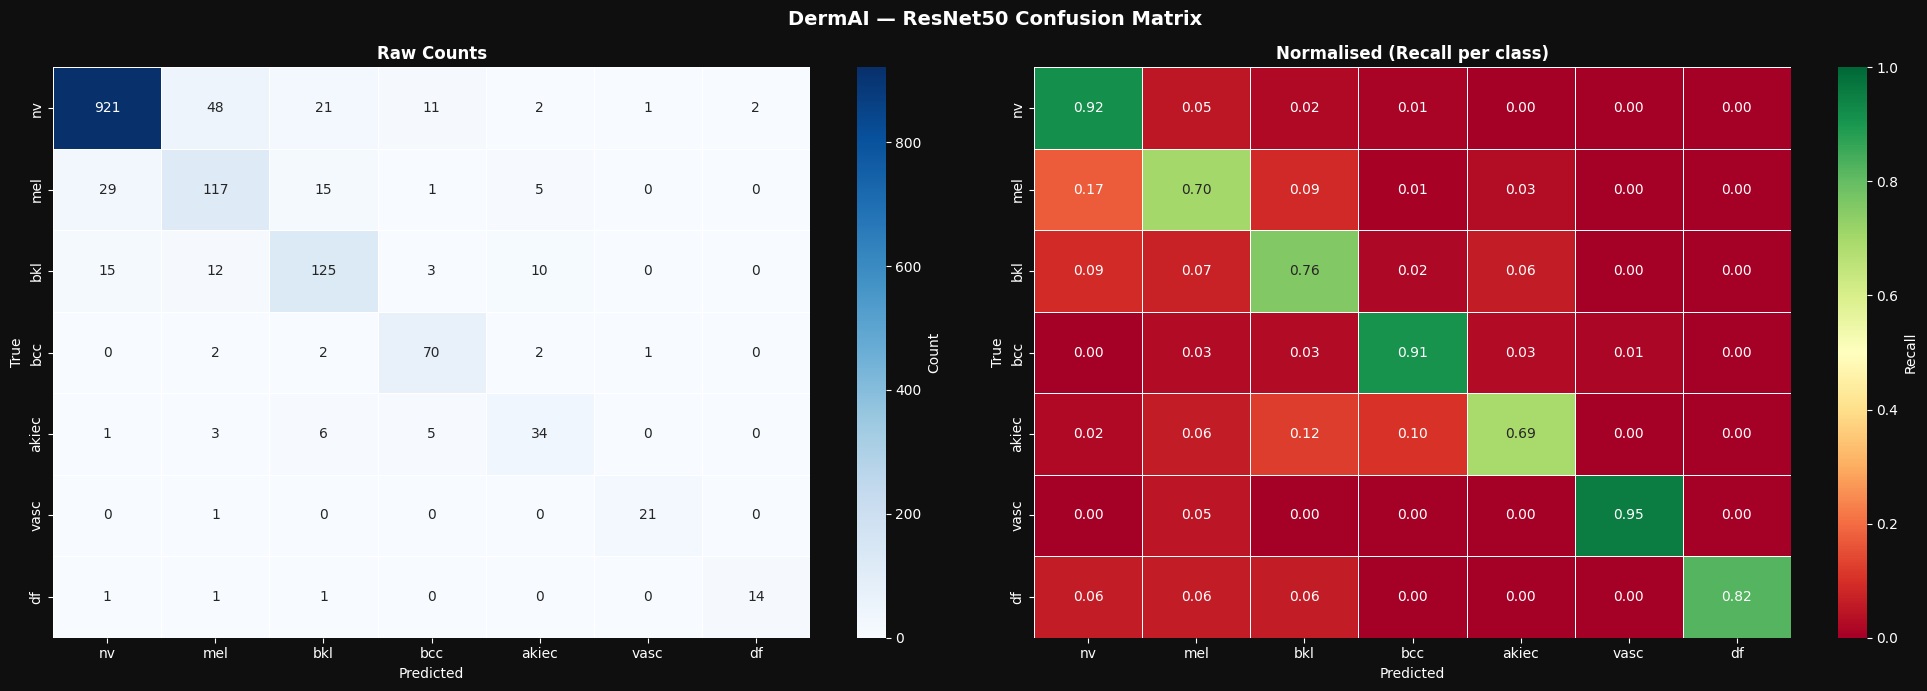

In [13]:
# ── CELL 11: Confusion Matrix ────────────────────────────────
cm = confusion_matrix(all_labels, all_preds)
cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)
 
fig, axes = plt.subplots(1, 2, figsize=(20, 7))
fig.suptitle('DermAI — ResNet50 Confusion Matrix',
             fontsize=14, fontweight='bold', color='white')
fig.patch.set_facecolor('#0f0f0f')
 
# Raw counts
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names_short,
            yticklabels=class_names_short,
            ax=axes[0], linewidths=0.5,
            cbar_kws={'label': 'Count'})
axes[0].set_title('Raw Counts', fontweight='bold', color='white')
axes[0].set_xlabel('Predicted', color='white')
axes[0].set_ylabel('True', color='white')
axes[0].tick_params(colors='white')
 
# Normalised
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='RdYlGn',
            xticklabels=class_names_short,
            yticklabels=class_names_short,
            ax=axes[1], linewidths=0.5, vmin=0, vmax=1,
            cbar_kws={'label': 'Recall'})
axes[1].set_title('Normalised (Recall per class)', fontweight='bold', color='white')
axes[1].set_xlabel('Predicted', color='white')
axes[1].set_ylabel('True', color='white')
axes[1].tick_params(colors='white')
 
plt.tight_layout()
plt.savefig('/kaggle/working/confusion_matrix_resnet50.png',
            dpi=150, bbox_inches='tight', facecolor='#0f0f0f')
plt.show()
 
 

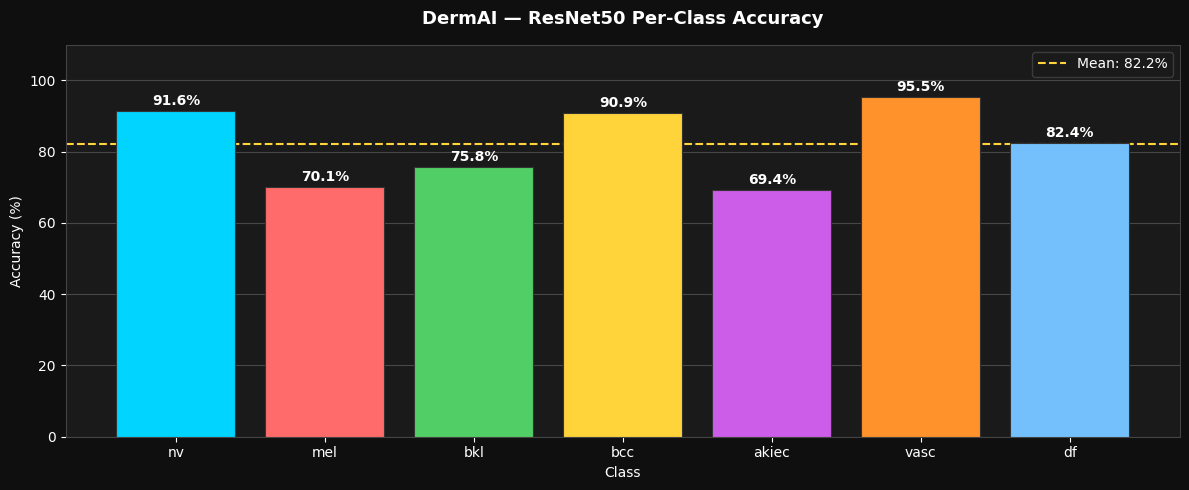


  Per-class accuracy:
  nv     (Melanocytic Nevi         ):  91.6%  ██████████████████
  mel    (Melanoma                 ):  70.1%  ██████████████
  bkl    (Benign Keratosis         ):  75.8%  ███████████████
  bcc    (Basal Cell Carcinoma     ):  90.9%  ██████████████████
  akiec  (Actinic Keratosis        ):  69.4%  █████████████
  vasc   (Vascular Lesions         ):  95.5%  ███████████████████
  df     (Dermatofibroma           ):  82.4%  ████████████████

  Mean accuracy     : 82.2%
  Overall val acc   : 86.95%


In [14]:
# ── CELL 12: Per-Class Accuracy Bar Chart ────────────────────
per_class_acc = cm_norm.diagonal() * 100
 
fig, ax = plt.subplots(figsize=(12, 5))
fig.patch.set_facecolor('#0f0f0f')
ax.set_facecolor('#1a1a1a')
 
bars = ax.bar(class_names_short, per_class_acc,
              color=PALETTE[:NUM_CLASSES], edgecolor='#333',
              linewidth=0.8, zorder=3)
 
for bar, acc in zip(bars, per_class_acc):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.8,
            f'{acc:.1f}%',
            ha='center', va='bottom',
            color='white', fontsize=10, fontweight='bold')
 
ax.axhline(y=np.mean(per_class_acc), color='#ffd43b',
           linestyle='--', linewidth=1.5,
           label=f'Mean: {np.mean(per_class_acc):.1f}%')
 
ax.set_title('DermAI — ResNet50 Per-Class Accuracy',
             fontsize=13, fontweight='bold', color='white', pad=15)
ax.set_xlabel('Class', color='white')
ax.set_ylabel('Accuracy (%)', color='white')
ax.set_ylim(0, 110)
ax.legend(fontsize=10)
ax.grid(True, axis='y', alpha=0.3, zorder=0)
ax.tick_params(colors='white')
 
plt.tight_layout()
plt.savefig('/kaggle/working/per_class_accuracy_resnet50.png',
            dpi=150, bbox_inches='tight', facecolor='#0f0f0f')
plt.show()
 
print(f"\n  Per-class accuracy:")
for cls, acc, (name, _, _) in zip(class_names_short,
                                   per_class_acc,
                                   CLASS_INFO.values()):
    bar = '█' * int(acc // 5)
    print(f"  {cls:6s} ({name:25s}): {acc:5.1f}%  {bar}")
 
print(f"\n  Mean accuracy     : {np.mean(per_class_acc):.1f}%")
print(f"  Overall val acc   : {best_val_acc:.2f}%")
 

In [18]:
# ============================================================
# STEP 17: EXPLAINABLE AI USING GRAD-CAM FOR RESNET50
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

# Remove old hooks if already created
try:
    gradcam.remove_hooks()
    print("Old Grad-CAM hooks removed.")
except:
    pass

# Load best trained ResNet50 model
model.load_state_dict(torch.load('/kaggle/working/best_resnet50.pth'))
model = model.to(DEVICE)
model.eval()

print("=" * 60)
print("EXPLAINABLE AI STARTED")
print("Method: Grad-CAM")
print("Model : ResNet50")
print("=" * 60)

EXPLAINABLE AI STARTED
Method: Grad-CAM
Model : ResNet50


In [20]:
# ============================================================
# STEP 18: SELECT TARGET LAYER FOR RESNET50
# ============================================================

# Best Grad-CAM layer for ResNet50
target_layer = model.layer4[-1]

print("=" * 60)
print("GRAD-CAM TARGET LAYER SELECTED")
print("=" * 60)
print(target_layer)
print("=" * 60)


# ============================================================
# STEP 19: GRAD-CAM CLASS
# ============================================================

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer

        self.gradients = None
        self.activations = None

        self.forward_hook = self.target_layer.register_forward_hook(
            self.save_activation
        )

        self.backward_hook = self.target_layer.register_full_backward_hook(
            self.save_gradient
        )

    def save_activation(self, module, input, output):
        self.activations = output.detach().clone()

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach().clone()

    def generate_cam(self, input_tensor, class_idx=None):
        self.model.zero_grad()

        output = self.model(input_tensor)

        if class_idx is None:
            class_idx = output.argmax(dim=1).item()

        score = output[:, class_idx]

        self.model.zero_grad()
        score.backward(retain_graph=True)

        gradients = self.gradients
        activations = self.activations

        weights = torch.mean(
            gradients,
            dim=(2, 3),
            keepdim=True
        )

        cam = torch.sum(weights * activations, dim=1)
        cam = F.relu(cam)

        cam = cam.squeeze().cpu().numpy()

        if np.max(cam) - np.min(cam) != 0:
            cam = cam - np.min(cam)
            cam = cam / (np.max(cam) + 1e-8)
        else:
            cam = np.zeros_like(cam)

        cam = cv2.resize(
            cam,
            (IMG_SIZE, IMG_SIZE)
        )

        return cam, class_idx

    def remove_hooks(self):
        self.forward_hook.remove()
        self.backward_hook.remove()


gradcam = GradCAM(
    model=model,
    target_layer=target_layer
)

print("Grad-CAM object created successfully.")


# ============================================================
# STEP 20: HELPER FUNCTIONS
# ============================================================

def denormalize_image(tensor_img, mean, std):
    image = tensor_img.cpu().numpy().transpose(1, 2, 0)

    mean = np.array(mean)
    std = np.array(std)

    image = image * std + mean
    image = np.clip(image, 0, 1)

    return image


def apply_gradcam_on_image(original_img, cam):
    heatmap = cv2.applyColorMap(
        np.uint8(255 * cam),
        cv2.COLORMAP_JET
    )

    heatmap = cv2.cvtColor(
        heatmap,
        cv2.COLOR_BGR2RGB
    )

    heatmap = np.float32(heatmap) / 255.0

    overlay = 0.45 * heatmap + 0.55 * original_img
    overlay = overlay / np.max(overlay)

    return heatmap, overlay

GRAD-CAM TARGET LAYER SELECTED
Bottleneck(
  (conv1): Conv2d(2048, 512, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(512, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn3): BatchNorm2d(2048, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
)
Grad-CAM object created successfully.


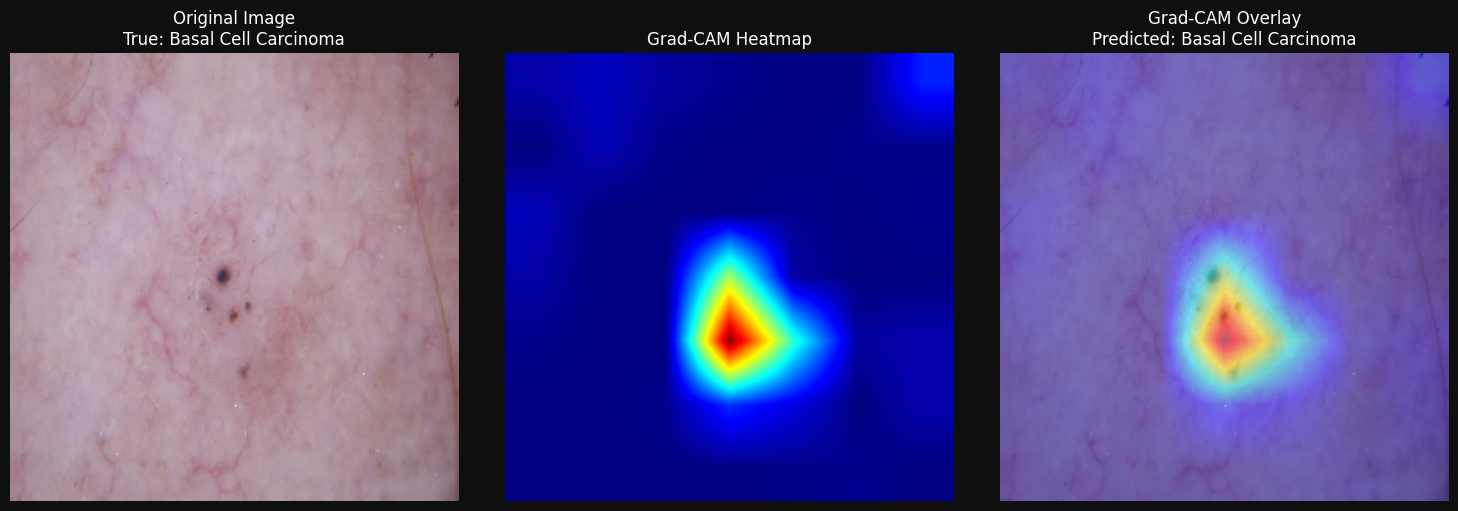

In [23]:
# ============================================================
# STEP 21: GRAD-CAM FOR ONE TEST IMAGE
# ============================================================

sample_index = 20

image_tensor, true_label = test_dataset[sample_index]

input_tensor = image_tensor.unsqueeze(0).to(DEVICE)

cam, predicted_label = gradcam.generate_cam(
    input_tensor=input_tensor
)

original_image = denormalize_image(
    image_tensor,
    MEAN,
    STD
)

heatmap, overlay = apply_gradcam_on_image(
    original_image,
    cam
)

true_class_code = IDX_TO_CLASS[true_label]
pred_class_code = IDX_TO_CLASS[predicted_label]

true_class_name = CLASS_INFO[true_class_code][0]
pred_class_name = CLASS_INFO[pred_class_code][0]

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title(f"Original Image\nTrue: {true_class_name}")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap)
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title(f"Grad-CAM Overlay\nPredicted: {pred_class_name}")
plt.axis("off")

plt.tight_layout()

plt.savefig(
    "/kaggle/working/resnet50_gradcam_single.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

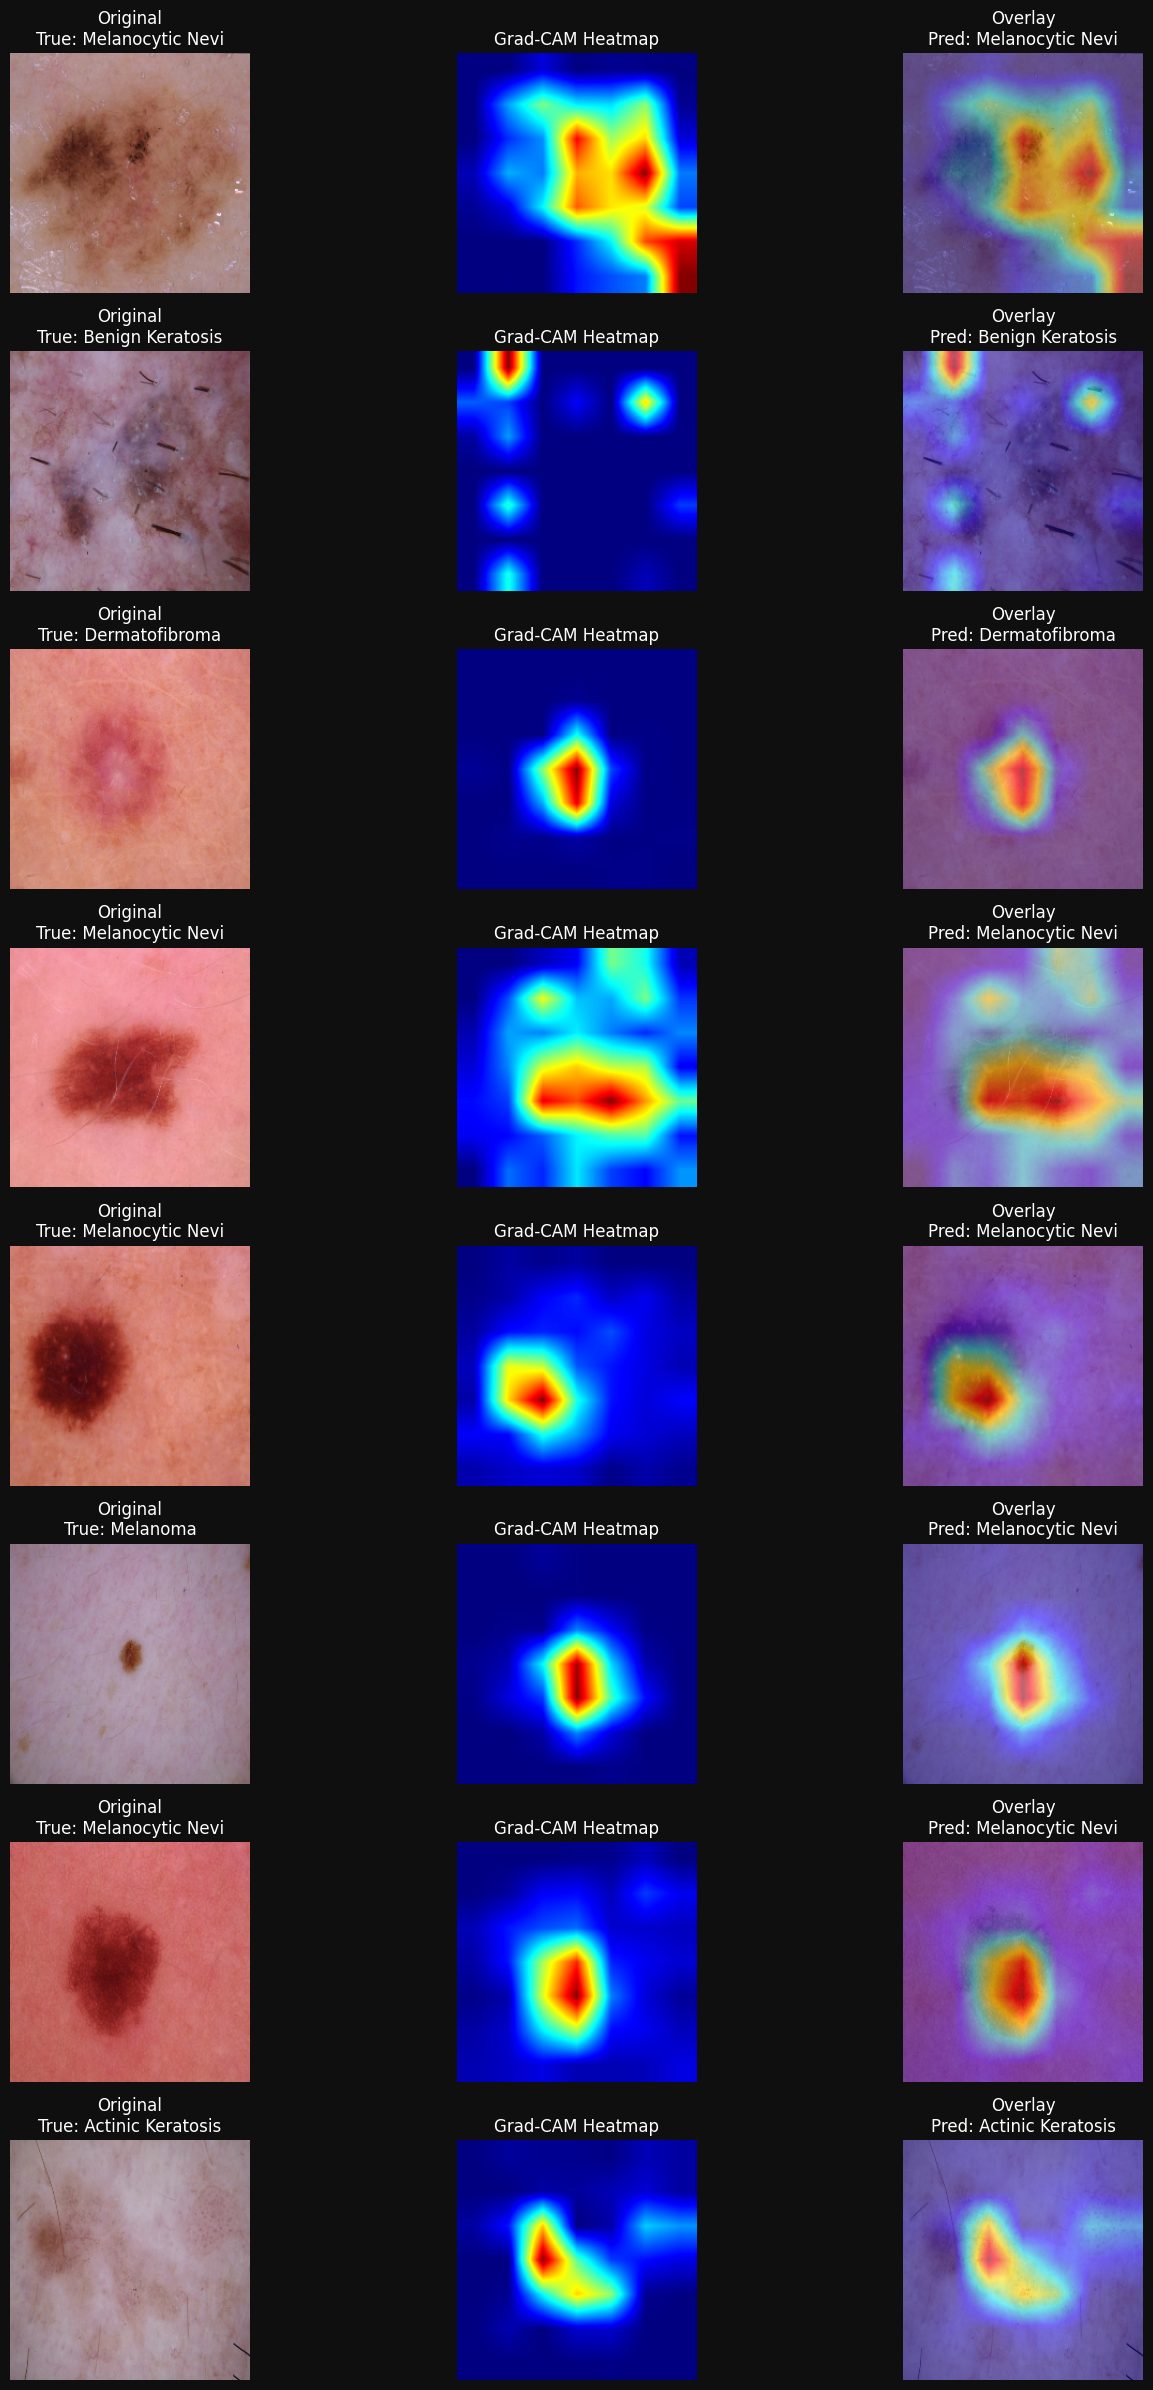

In [24]:
# ============================================================
# STEP 22: GRAD-CAM FOR MULTIPLE TEST IMAGES
# ============================================================

def show_gradcam_multiple_images(dataset, model, gradcam, num_samples=8):
    model.eval()

    plt.figure(figsize=(15, num_samples * 3))

    for i in range(num_samples):
        image_tensor, true_label = dataset[i]

        input_tensor = image_tensor.unsqueeze(0).to(DEVICE)

        cam, predicted_label = gradcam.generate_cam(
            input_tensor=input_tensor
        )

        original_image = denormalize_image(
            image_tensor,
            MEAN,
            STD
        )

        heatmap, overlay = apply_gradcam_on_image(
            original_image,
            cam
        )

        true_class_code = IDX_TO_CLASS[true_label]
        pred_class_code = IDX_TO_CLASS[predicted_label]

        true_class_name = CLASS_INFO[true_class_code][0]
        pred_class_name = CLASS_INFO[pred_class_code][0]

        plt.subplot(num_samples, 3, i * 3 + 1)
        plt.imshow(original_image)
        plt.title(f"Original\nTrue: {true_class_name}")
        plt.axis("off")

        plt.subplot(num_samples, 3, i * 3 + 2)
        plt.imshow(heatmap)
        plt.title("Grad-CAM Heatmap")
        plt.axis("off")

        plt.subplot(num_samples, 3, i * 3 + 3)
        plt.imshow(overlay)
        plt.title(f"Overlay\nPred: {pred_class_name}")
        plt.axis("off")

    plt.tight_layout()

    plt.savefig(
        "/kaggle/working/resnet50_gradcam_multiple.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()


show_gradcam_multiple_images(
    dataset=test_dataset,
    model=model,
    gradcam=gradcam,
    num_samples=8
)